Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
FoodVision Object Detection
Device: cpu
Tip: Enable GPU in Colab for faster inference.


Saving burger.jpg to burger.jpg

Image uploaded: burger.jpg


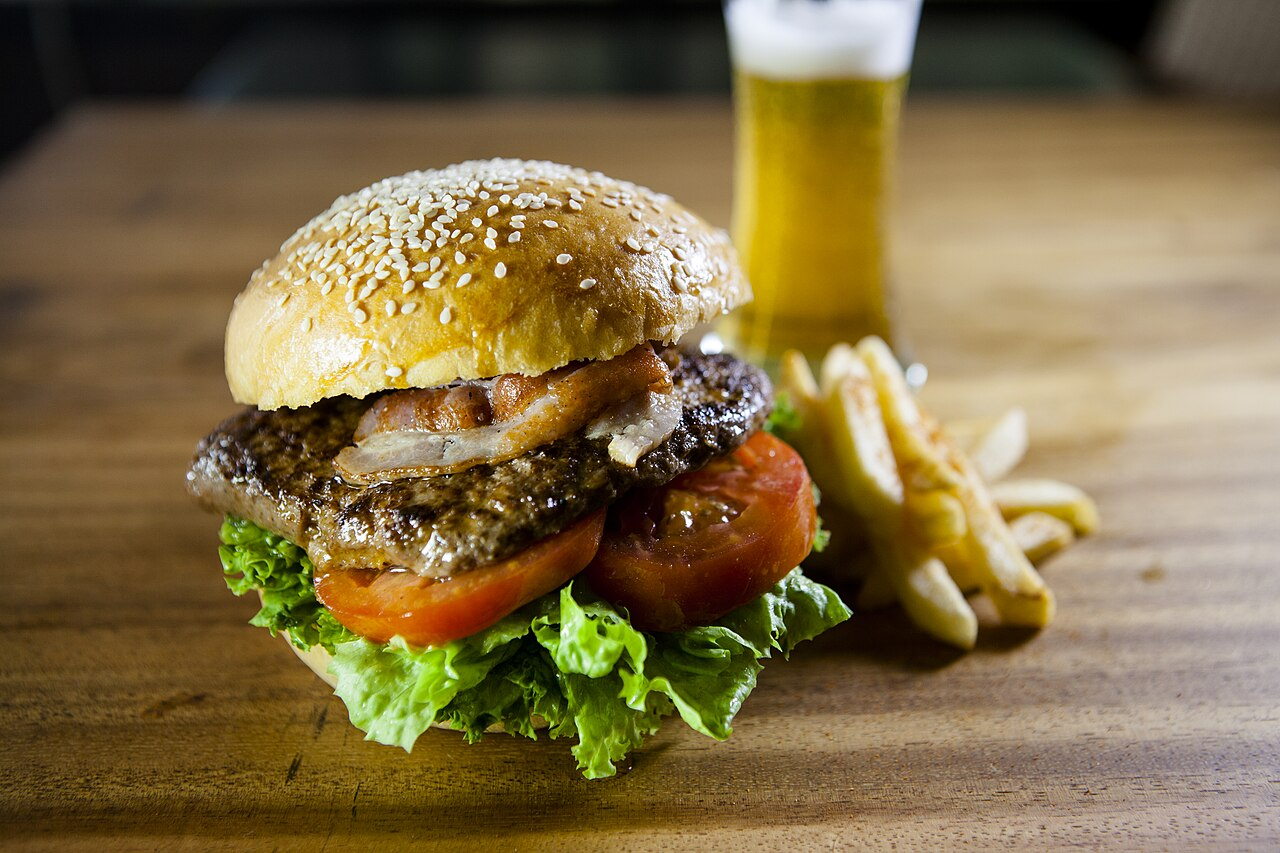


Loading models...
WARNING ⚠️ Download failure, retrying 1/3 in 5s https://github.com/ultralytics/assets/releases/download/v8.4.0/yolo26n.pt... 503 Server Error: Service Unavailable for url: https://github.com/ultralytics/assets/releases/download/v8.4.0/yolo26n.pt
WARNING ⚠️ Download failure, retrying 2/3 in 10s https://github.com/ultralytics/assets/releases/download/v8.4.0/yolo26n.pt... 503 Server Error: Service Unavailable for url: https://github.com/ultralytics/assets/releases/download/v8.4.0/yolo26n.pt
YOLO loaded
Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth


100%|██████████| 167M/167M [00:01<00:00, 94.6MB/s]


Faster R-CNN loaded
RT-DETR loaded

Total loading time: 154.77 seconds

Running YOLO26n...


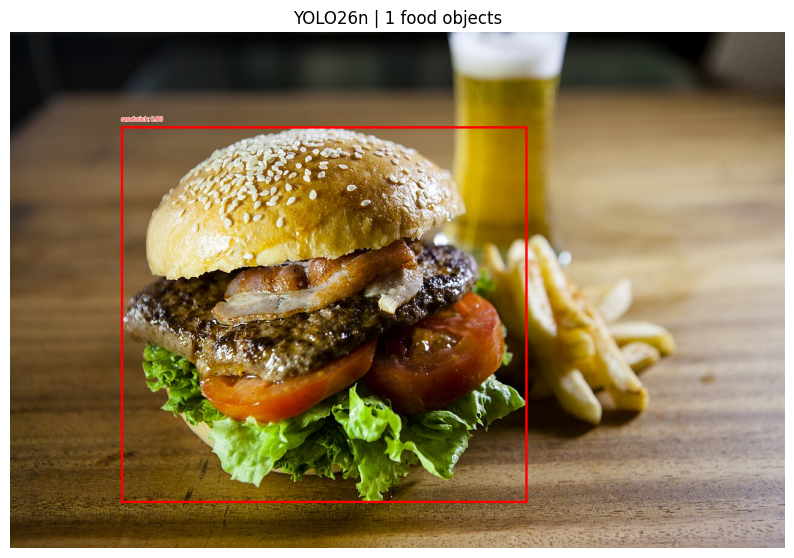


Running Faster R-CNN...


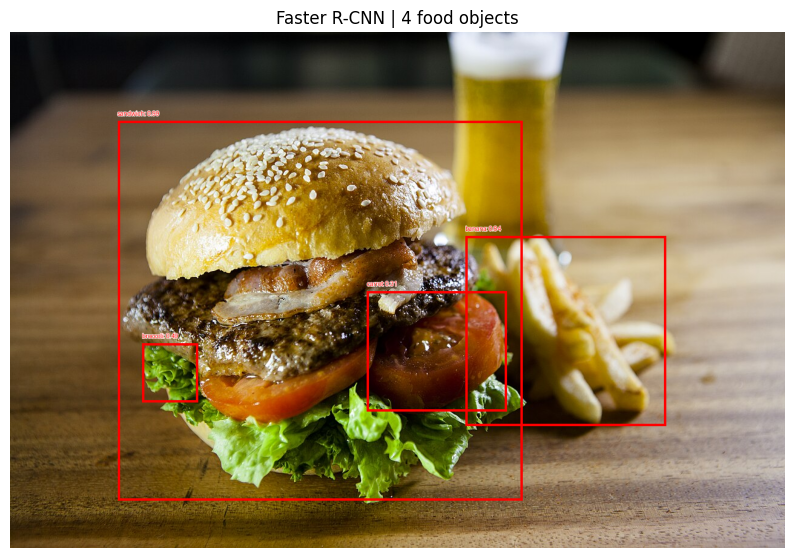


Running RT-DETR-L...


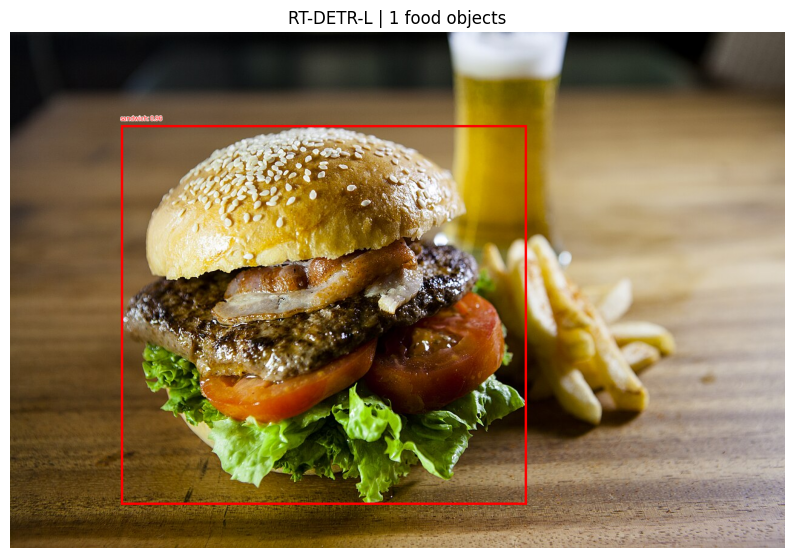


FOODVISION BENCHMARK SUMMARY


,Model,Food Objects,Inference (ms),Detected Labels
0,YOLO26n,1,186.88,sandwich
1,Faster R-CNN,4,14339.06,"sandwich, banana, broccoli, carrot"
2,RT-DETR-L,1,1953.17,sandwich



Experiment completed.
Device: cpu
Confidence threshold: 0.25


In [1]:

# ============================================================
# FOODVISION: 3 OBJECT DETECTION MODELS
# YOLO26n vs Faster R-CNN vs RT-DETR
# Google Colab - Single Cell
# ============================================================

# 1. INSTALL AND IMPORT
!pip -q install ultralytics

import torch
import time
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageDraw
from google.colab import files
from ultralytics import YOLO, RTDETR
from torchvision.models.detection import (
    fasterrcnn_resnet50_fpn_v2,
    FasterRCNN_ResNet50_FPN_V2_Weights
)

from IPython.display import display

# 2. CONFIGURATION

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
CONFIDENCE = 0.25

# Common food categories in COCO dataset
FOOD_CLASSES = {
    "banana", "apple", "orange", "broccoli",
    "carrot", "sandwich", "hot dog",
    "pizza", "donut", "cake"
}

print("FoodVision Object Detection")
print("===========================")
print("Device:", DEVICE)

if DEVICE == "cpu":
    print("Tip: Enable GPU in Colab for faster inference.")

# 3. UPLOAD IMAGE

uploaded = files.upload()

if not uploaded:
    raise ValueError("Please upload an image.")

filename = next(iter(uploaded))
image = Image.open(filename).convert("RGB")

print("\nImage uploaded:", filename)
display(image)

# 4. LOAD MODELS

print("\nLoading models...")

start = time.time()
yolo_model = YOLO("yolo26n.pt")
print("YOLO loaded")

weights = FasterRCNN_ResNet50_FPN_V2_Weights.DEFAULT
faster_model = fasterrcnn_resnet50_fpn_v2(
    weights=weights
).to(DEVICE).eval()
faster_transform = weights.transforms()
faster_categories = weights.meta["categories"]
print("Faster R-CNN loaded")

rtdetr_model = RTDETR("rtdetr-l.pt")
print("RT-DETR loaded")

print(f"\nTotal loading time: {time.time()-start:.2f} seconds")

# 5. COMMON OUTPUT FORMAT

def synchronize():
    if DEVICE == "cuda":
        torch.cuda.synchronize()

def filter_food(detections):
    return [
        d for d in detections
        if d["label"].lower() in FOOD_CLASSES
    ]

# 6. YOLO DETECTION

def detect_yolo(image):
    results = yolo_model.predict(
        source=image,
        conf=CONFIDENCE,
        verbose=False
    )[0]

    detections = []

    if results.boxes is not None:
        for box in results.boxes:
            class_id = int(box.cls[0])
            label = results.names[class_id]
            confidence = float(box.conf[0])
            x1, y1, x2, y2 = box.xyxy[0].tolist()

            detections.append({
                "label": label,
                "confidence": confidence,
                "box": [x1, y1, x2, y2]
            })

    return filter_food(detections)

# 7. FASTER R-CNN DETECTION

def detect_faster(image):
    tensor = faster_transform(image).to(DEVICE)

    with torch.inference_mode():
        prediction = faster_model([tensor])[0]

    detections = []

    for box, label_id, score in zip(
        prediction["boxes"],
        prediction["labels"],
        prediction["scores"]
    ):
        label = faster_categories[int(label_id)]
        confidence = float(score)

        if confidence >= CONFIDENCE:
            x1, y1, x2, y2 = box.cpu().tolist()

            detections.append({
                "label": label,
                "confidence": confidence,
                "box": [x1, y1, x2, y2]
            })

    return filter_food(detections)

# 8. RT-DETR DETECTION

def detect_rtdetr(image):
    results = rtdetr_model.predict(
        source=image,
        conf=CONFIDENCE,
        verbose=False
    )[0]

    detections = []

    if results.boxes is not None:
        for box in results.boxes:
            class_id = int(box.cls[0])
            label = results.names[class_id]
            confidence = float(box.conf[0])
            x1, y1, x2, y2 = box.xyxy[0].tolist()

            detections.append({
                "label": label,
                "confidence": confidence,
                "box": [x1, y1, x2, y2]
            })

    return filter_food(detections)

# 9. VISUALIZE DETECTIONS

def draw_results(image, detections, title):
    output = image.copy()
    draw = ImageDraw.Draw(output)

    for d in detections:
        x1, y1, x2, y2 = d["box"]
        label = d["label"]
        confidence = d["confidence"]

        draw.rectangle(
            [x1, y1, x2, y2],
            outline="red",
            width=4
        )

        text = f"{label}: {confidence:.2f}"

        draw.text(
            (x1, max(0, y1 - 18)),
            text,
            fill="red",
            stroke_width=1,
            stroke_fill="white"
        )

    plt.figure(figsize=(10, 7))
    plt.imshow(output)
    plt.title(f"{title} | {len(detections)} food objects")
    plt.axis("off")
    plt.show()

# 10. RUN BENCHMARK

models = {
    "YOLO26n": detect_yolo,
    "Faster R-CNN": detect_faster,
    "RT-DETR-L": detect_rtdetr
}

benchmark = []
all_results = {}

for name, detector in models.items():

    print(f"\nRunning {name}...")

    try:
        # Warm-up pass
        detector(image)

        synchronize()
        start = time.perf_counter()

        detections = detector(image)

        synchronize()
        elapsed = (time.perf_counter() - start) * 1000

        all_results[name] = detections

        benchmark.append({
            "Model": name,
            "Food Objects": len(detections),
            "Inference (ms)": round(elapsed, 2),
            "Detected Labels": ", ".join(
                d["label"] for d in detections
            ) or "None"
        })

        draw_results(image, detections, name)

    except Exception as e:
        print(f"ERROR in {name}: {e}")

# 11. BENCHMARK SUMMARY

print("\nFOODVISION BENCHMARK SUMMARY")
print("============================")

df = pd.DataFrame(benchmark)
display(df)

print("\nExperiment completed.")
print("Device:", DEVICE)
print("Confidence threshold:", CONFIDENCE)
